Learning Rate: 0.01
Epochs: 3000
Test Rows: 175295
MAE: 17.082978246787466
MSE: 569.109800543163
RMSE: 23.85602231184325
R2 Score: 0.8999216889446191


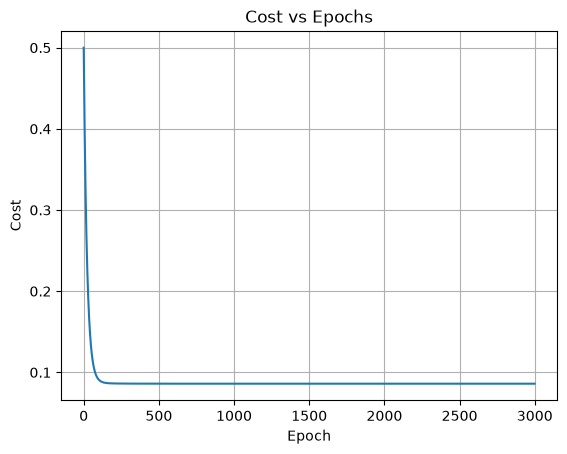

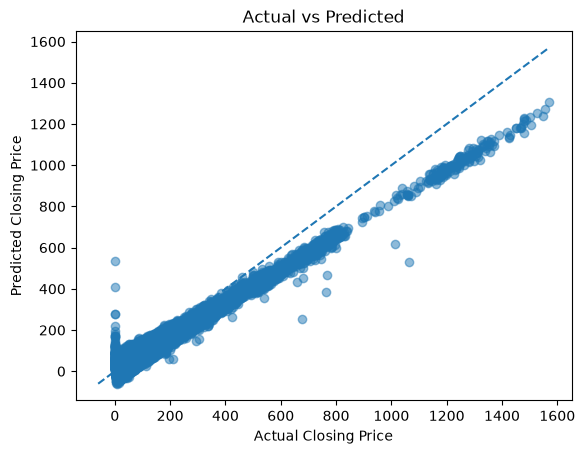

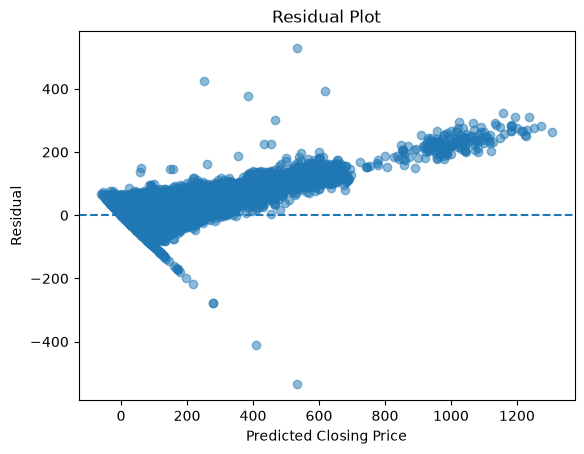

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



def load_data():
    train = pd.read_csv("train_data1.csv")
    test = pd.read_csv("test_data1.csv")

    X_train = train[["open", "high", "low", "volume"]].values
    y_train = train["close"].values

    X_test = test[["open", "high", "low", "volume"]].values
    y_test = test["close"].values

    return X_train, y_train, X_test, y_test



def normalize(X_train, X_test, y_train):
    x_mean = X_train.mean(axis=0)
    x_std = X_train.std(axis=0)
    x_std[x_std == 0] = 1

    X_train = (X_train - x_mean) / x_std
    X_test = (X_test - x_mean) / x_std

    y_mean = y_train.mean()
    y_std = y_train.std()

    if y_std == 0:
        raise ValueError("Training target has zero variance.")

    y_train = (y_train - y_mean) / y_std

    return X_train, X_test, y_train, y_mean, y_std


def train_model(X, y, lr=0.01, epochs=3000):
    m, n = X.shape
    w = np.zeros(n)
    b = 0
    costs = []

    for i in range(epochs):
        pred = X @ w + b
        error = pred - y

        dw = X.T @ error / m
        db = np.mean(error)

        w -= lr * dw
        b -= lr * db

        costs.append(np.mean(error ** 2) / 2)

    return w, b, costs


def predict(X, w, b, y_mean, y_std):
    return (X @ w + b) * y_std + y_mean


def evaluate(y_true, y_pred):
    error = y_true - y_pred

    mae = np.mean(np.abs(error))
    mse = np.mean(error ** 2)
    rmse = np.sqrt(mse)

    ss_total = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - np.sum(error ** 2) / ss_total if ss_total != 0 else float("nan")

    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)



def plot_graphs(costs, y_test, y_pred):
    plt.plot(costs)
    plt.title("Cost vs Epochs")
    plt.xlabel("Epoch")
    plt.ylabel("Cost")
    plt.grid()
    plt.show()

    plt.scatter(y_test, y_pred, alpha=0.5)
    low = min(y_test.min(), y_pred.min())
    high = max(y_test.max(), y_pred.max())
    plt.plot([low, high], [low, high], "--")
    plt.xlabel("Actual Closing Price")
    plt.ylabel("Predicted Closing Price")
    plt.title("Actual vs Predicted")
    plt.show()

    residuals = y_test - y_pred
    plt.scatter(y_pred, residuals, alpha=0.5)
    plt.axhline(0, linestyle="--")
    plt.xlabel("Predicted Closing Price")
    plt.ylabel("Residual")
    plt.title("Residual Plot")
    plt.show()



X_train, y_train, X_test, y_test = load_data()

X_train, X_test, y_scaled, y_mean, y_std = normalize(
    X_train, X_test, y_train
)

learning_rate = 0.01
epochs = 3000

w, b, costs = train_model(
    X_train, y_scaled, learning_rate, epochs
)

y_pred = predict(X_test, w, b, y_mean, y_std)

print("Learning Rate:", learning_rate)
print("Epochs:", epochs)
print("Test Rows:", len(y_test))

evaluate(y_test, y_pred)
plot_graphs(costs, y_test, y_pred)

In [11]:

def find_learning_rate(X, y):
    rates = [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5]
    epochs = 3000

    m, n = X.shape
    results = []

    for lr in rates:
        w = np.zeros(n)
        b = 0.0
        cost = []

        for i in range(epochs):
            pred = X @ w + b
            error = pred - y

            dw = (X.T @ error) / m
            db = np.mean(error)

            w -= lr * dw
            b -= lr * db

            current_cost = np.mean((X @ w + b - y) ** 2) / 2
            cost.append(current_cost)

            if not np.isfinite(current_cost):
                break

        if len(cost) > 0 and np.isfinite(cost[-1]):
            results.append((lr, cost[-1]))
            print("Learning rate:", lr, "| Final cost:", cost[-1])
        else:
            print("Learning rate:", lr, "| Diverged")

    if not results:
        print("No stable learning rate found.")
        return None

    best_lr = min(results, key=lambda item: item[1])[0]
    print("\nBest learning rate by final training cost:", best_lr)

    return best_lr



best_lr = find_learning_rate(X_train, y_scaled)

Learning rate: 0.0001 | Final cost: 0.1936481058812428
Learning rate: 0.001 | Final cost: 0.08614920801083466
Learning rate: 0.01 | Final cost: 0.08603650931209107
Learning rate: 0.05 | Final cost: 0.08603650931181962
Learning rate: 0.1 | Final cost: 0.08603650931181962
Learning rate: 0.5 | Final cost: 0.08603650931181962

Best learning rate by final training cost: 0.05


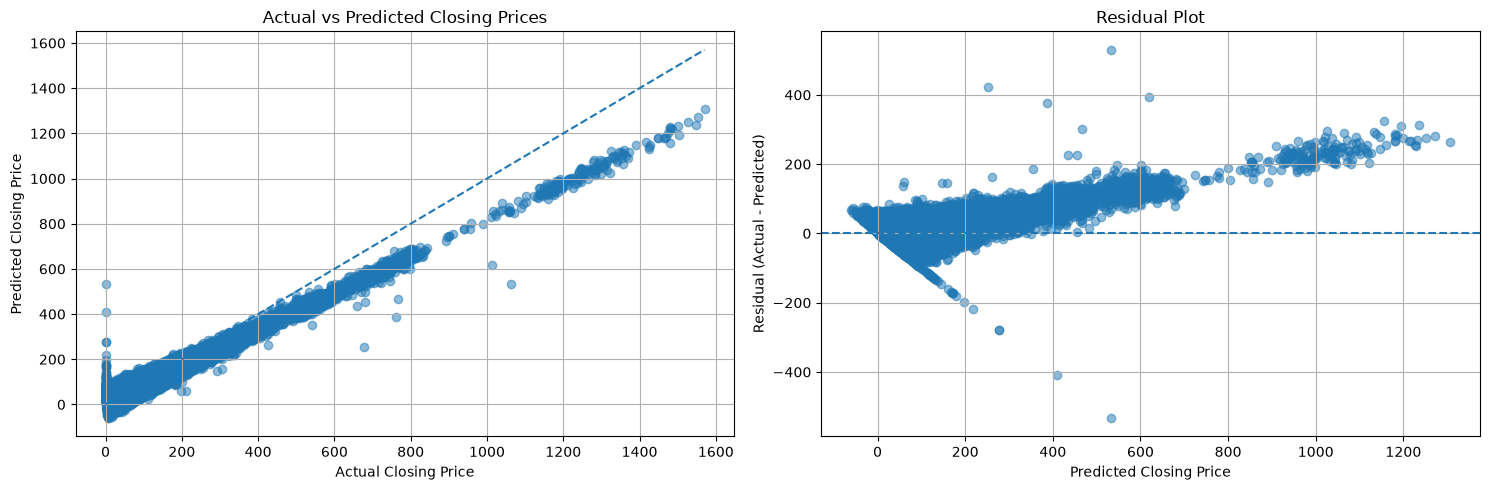

: 

In [ ]:

import matplotlib.pyplot as plt
import numpy as np


residuals = y_test - y_pred


fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].scatter(y_test, y_pred, alpha=0.5)
ax[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
ax[0].set_title("Actual vs Predicted Closing Prices")
ax[0].set_xlabel("Actual Closing Price")
ax[0].set_ylabel("Predicted Closing Price")
ax[0].grid(True)


ax[1].scatter(y_pred, residuals, alpha=0.5)
ax[1].axhline(y=0, linestyle="--")
ax[1].set_title("Residual Plot")
ax[1].set_xlabel("Predicted Closing Price")
ax[1].set_ylabel("Residual (Actual - Predicted)")
ax[1].grid(True)

plt.tight_layout()
plt.show()